# Extended Embedding Model Sweep — V5 Candidate Search

**Goal**: Find a zero-shot embedding model that beats Nomic-embed-text-v1.5 (Spearman=0.4476) on the grounded resolution-notes benchmark.

**Benchmark**: `benchmark_v4_semantic_resnotes.json` — 950 pairs, TF-IDF of resolution notes as ground truth (the only meaningful benchmark we have).

**Baseline to beat**: Nomic-embed-text-v1.5 → Spearman=0.4476, ROC-AUC=0.7584

| Model | Dim | Key advantage |
|-------|-----|---------------|
| `BAAI/bge-m3` | 1024 | Multi-vector, state-of-art retrieval, no prefixes |
| `mixedbread-ai/mxbai-embed-large-v1` | 1024 | Top MTEB retrieval, asymmetric search |
| `BAAI/bge-large-en-v1.5` | 1024 | Large BGE (base scored 0.3654) |
| `intfloat/e5-large-v2` | 1024 | Large E5 (base scored 0.3579) |
| `intfloat/multilingual-e5-large-instruct` | 1024 | Instruction-tuned E5 (replaces Jina — unloadable) |
| `Snowflake/snowflake-arctic-embed-l` | 1024 | Open MTEB retrieval model (mask patched post-load) |
| `google/embeddinggemma-300m` | 768 | Gemma-based model (Feb 2026) — gated, HF login required |
| `Alibaba-NLP/gte-Qwen2-1.5B-instruct` | 1536 | #1 MTEB, 8192-token — needs transformers ≥ 4.40 + kernel restart |

**Setup**: Run cell 3 (upgrade + HF login) → **restart kernel** → run cells 1 → 5 (cleanup) → 6 → 7.
Existing results loaded from `zero_shot_sweep_v4.json`.


In [1]:
# ── 1. Imports & Paths ─────────────────────────────────────────────────────
import json
import gc
import random
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE       = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism')
DATA_NEW   = BASE / 'data_new'
EVAL_DIR   = BASE / 'models' / 'eval_v3_results'

# Benchmark files (pre-built by evaluate_v4_benchmark.ipynb)
SEMANTIC_PATH  = DATA_NEW / 'benchmark_v4_semantic_resnotes.json'
GROUP_CAT_PATH = DATA_NEW / 'benchmark_v4_group_category.json'
RSCODE_PATH    = DATA_NEW / 'benchmark_v4_resolution_code.json'

# Baseline results from previous sweep
BASELINE_PATH  = EVAL_DIR / 'zero_shot_sweep_v4.json'

# Output for this sweep
RESULTS_PATH   = EVAL_DIR / 'extended_sweep_v5.json'
EVAL_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device : {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device : cuda
GPU    : NVIDIA GeForce RTX 5090
VRAM   : 34.2 GB


In [2]:
# ── 2. Load Benchmarks & Baseline ─────────────────────────────────────────
assert SEMANTIC_PATH.exists(),  f'Missing: {SEMANTIC_PATH}'
assert GROUP_CAT_PATH.exists(), f'Missing: {GROUP_CAT_PATH}'
assert RSCODE_PATH.exists(),    f'Missing: {RSCODE_PATH}'

semantic_pairs  = json.loads(SEMANTIC_PATH.read_text(encoding='utf-8'))
group_cat_pairs = json.loads(GROUP_CAT_PATH.read_text(encoding='utf-8'))
rscode_pairs    = json.loads(RSCODE_PATH.read_text(encoding='utf-8'))

# Strip internal sanity-check fields
semantic_pairs_clean = [
    {k: v for k, v in p.items() if not k.startswith('_')}
    for p in semantic_pairs
]

BENCHMARKS = {
    'v4_semantic_resnotes': semantic_pairs_clean,   # PRIMARY — grounded
    'v4_group_cat'        : group_cat_pairs,
    'v4_rescode'          : rscode_pairs,
}

for name, pairs in BENCHMARKS.items():
    pos = sum(p['label'] == 1 for p in pairs)
    print(f'{name:35s}: {len(pairs)} pairs | pos={pos} neg={len(pairs)-pos}')

# Load baseline for reference
baseline = {}
if BASELINE_PATH.exists():
    baseline = json.loads(BASELINE_PATH.read_text(encoding='utf-8'))
    print(f'\nBaseline results loaded — {len(baseline)} models')
    nomic_sp = baseline.get('Nomic-embed-text-v1.5', {}).get('v4_semantic_resnotes', {}).get('spearman', 'N/A')
    print(f'Baseline to beat: Nomic-embed-text-v1.5  Spearman={nomic_sp}')

# Load existing extended results if resuming
results = {}
if RESULTS_PATH.exists():
    results = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
    print(f'Resuming: {len(results)} models already evaluated')

v4_semantic_resnotes               : 950 pairs | pos=475 neg=475
v4_group_cat                       : 950 pairs | pos=475 neg=475
v4_rescode                         : 950 pairs | pos=475 neg=475

Baseline results loaded — 7 models
Baseline to beat: Nomic-embed-text-v1.5  Spearman=0.4476
Resuming: 8 models already evaluated


In [3]:

# ── 2b. Transformers upgrade + HuggingFace login ───────────────────────────
# ⚠️  After running this cell, RESTART THE KERNEL, then run cells 1→5 again.
import subprocess, sys, os
from pathlib import Path

# 1. Upgrade transformers for GTE-Qwen2 rope_theta support
result = subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '--upgrade', 'transformers', '-q'],
    capture_output=True, text=True
)
if result.returncode == 0:
    import transformers as _tf
    print(f'transformers upgraded — version {_tf.__version__}')
else:
    print('pip upgrade FAILED:')
    print(result.stderr[-500:])

# 2. Load HUGGINGFACE_TOKEN from nexustism/.env
_env_file = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\.env')
if _env_file.exists():
    for _line in _env_file.read_text(encoding='utf-8').splitlines():
        _line = _line.strip()
        if not _line or _line.startswith('#') or '=' not in _line:
            continue
        _k, _v = _line.split('=', 1)
        os.environ[_k.strip()] = _v.strip().strip('"').strip("'")
    print(f'Loaded .env from {_env_file}')
else:
    print(f'.env not found at {_env_file} — relying on existing env vars')

# 3. HuggingFace login using HUGGINGFACE_TOKEN
try:
    from huggingface_hub import login as _hf_login, whoami as _hf_whoami
    hf_token = (
        os.environ.get('HUGGINGFACE_TOKEN') or
        os.environ.get('HF_TOKEN')
    )
    if hf_token:
        _hf_login(token=hf_token, add_to_git_credential=False)
        print(f'HuggingFace: logged in → {_hf_whoami()["name"]}')
    else:
        info = _hf_whoami()   # try cached token
        print(f'HuggingFace: using cached credentials → {info["name"]}')
except Exception as e:
    print(f'HuggingFace login FAILED: {e}')
    print('  → Check that HUGGINGFACE_TOKEN is set in nexustism/.env')

print('\n⚠️  RESTART KERNEL NOW, then run cells 1 → 5 again.')


transformers upgraded — version 5.2.0
Loaded .env from c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\.env
HuggingFace: logged in → Sobaab

⚠️  RESTART KERNEL NOW, then run cells 1 → 5 again.


In [28]:

# ── 3. Compatibility shim + Jina wrapper + Eval function ──────────────────

# ── Shim: DynamicCache API changes in transformers 5.x ───────────────────
# Several DynamicCache methods used by GTE-Qwen2 trust_remote_code were
# removed or renamed in transformers 5.x.  Patch them all at once.
try:
    from transformers.cache_utils import DynamicCache as _DC
    _dc_patched = []

    def _dc_past_length(self, layer_idx=0):
        """Safely get cached past sequence length regardless of 4.x vs 5.x internals."""
        # transformers 4.x: key_cache / value_cache list of tensors
        try:
            kc = object.__getattribute__(self, 'key_cache')
            if kc and layer_idx < len(kc) and kc[layer_idx] is not None:
                return int(kc[layer_idx].shape[-2])
        except AttributeError:
            pass
        # transformers 5.x: may use _cache dict or similar
        for attr in ('_cache', 'cache'):
            try:
                d = object.__getattribute__(self, attr)
                if isinstance(d, dict) and layer_idx in d:
                    return int(d[layer_idx][0].shape[-2])
            except (AttributeError, TypeError, IndexError):
                pass
        # Fallback: try the native get_seq_length if it exists under another name
        for method in ('_get_seq_length', '_seq_length'):
            try:
                return int(getattr(self, method)(layer_idx))
            except Exception:
                pass
        return 0

    # from_legacy_cache(past_key_values) → DynamicCache
    if not hasattr(_DC, 'from_legacy_cache'):
        @classmethod
        def _from_legacy_cache(cls, past_key_values=None):
            if past_key_values is None:
                return cls()
            cache = cls()
            for layer_idx, (k, v) in enumerate(past_key_values):
                cache.update(k, v, layer_idx)
            return cache
        _DC.from_legacy_cache = _from_legacy_cache
        _dc_patched.append('from_legacy_cache')

    # to_legacy_cache() → always overwrite (may have been set to broken version)
    def _to_legacy_cache(self):
        try:
            kc = object.__getattribute__(self, 'key_cache')
            vc = object.__getattribute__(self, 'value_cache')
            return tuple(zip(kc, vc))
        except AttributeError:
            return ()
    _DC.to_legacy_cache = _to_legacy_cache
    _dc_patched.append('to_legacy_cache (overwrite)')

    # get_usable_length(new_seq_len, layer_idx) → always overwrite
    # GTE-Qwen2 uses a bidirectional position trick: for fresh inference
    # (no past KV), the attention mask must cover 2×seq_len positions.
    # When past IS present, return past_len + new_seq_len as normal.
    def _get_usable_length(self, new_seq_length, layer_idx=0):
        past = _dc_past_length(self, layer_idx)
        if past == 0:
            return new_seq_length * 2   # bidirectional trick: key space = 2×query
        return new_seq_length + past
    _DC.get_usable_length = _get_usable_length
    _dc_patched.append('get_usable_length (overwrite)')

    # get_seq_length(layer_idx) → always overwrite
    def _get_seq_length(self, layer_idx=0):
        return _dc_past_length(self, layer_idx)
    _DC.get_seq_length = _get_seq_length
    _dc_patched.append('get_seq_length (overwrite)')

    # get_max_length() → None (no fixed max in DynamicCache)
    if not hasattr(_DC, 'get_max_length'):
        def _get_max_length(self):
            return None
        _DC.get_max_length = _get_max_length
        _dc_patched.append('get_max_length')

    if _dc_patched:
        print(f'DynamicCache shims injected: {_dc_patched}')
    else:
        print('DynamicCache: all methods present natively — no shims needed')
except ImportError as _e:
    print(f'DynamicCache shim skipped: {_e}')


# ── Shim: Qwen2 tokenizer module path restructured in transformers 5.x ────
# trust_remote_code in GTE-Qwen2 imports from
# 'transformers.models.qwen2.tokenization_qwen2_fast' which no longer exists
# as a sub-module in transformers 5.x.  Inject a stub that re-exports
# Qwen2TokenizerFast from wherever transformers 5.x actually puts it.
import sys as _sys, types as _types
if 'transformers.models.qwen2.tokenization_qwen2_fast' not in _sys.modules:
    try:
        _stub = _types.ModuleType('transformers.models.qwen2.tokenization_qwen2_fast')
        try:
            from transformers.models.qwen2 import Qwen2TokenizerFast as _Q2TF
        except ImportError:
            from transformers import Qwen2TokenizerFast as _Q2TF
        _stub.Qwen2TokenizerFast = _Q2TF
        import transformers.models.qwen2 as _q2mod
        if not hasattr(_q2mod, 'tokenization_qwen2_fast'):
            setattr(_q2mod, 'tokenization_qwen2_fast', _stub)
        _sys.modules['transformers.models.qwen2.tokenization_qwen2_fast'] = _stub
        print('Qwen2TokenizerFast module shim injected')
    except Exception as _e:
        print(f'Qwen2 tokenizer shim FAILED: {_e}')
else:
    print('Qwen2TokenizerFast module already present — no shim needed')


# ── Shim: 'merge_with_config_defaults' was removed in transformers >= 4.40 ──
# Jina v3, Snowflake, and some other models' trust_remote_code still imports
# it.  We re-inject a safe passthrough into the module so their code finds it.
import transformers.utils.generic as _tug
if not hasattr(_tug, 'merge_with_config_defaults'):
    def _merge_compat(config, defaults=None):
        """Passthrough shim for removed transformers function."""
        if defaults is None:
            return config
        if isinstance(config, dict) and isinstance(defaults, dict):
            return {**defaults, **config}
        # For config objects: set missing attributes from defaults
        if isinstance(defaults, dict):
            for k, v in defaults.items():
                if not hasattr(config, k) or getattr(config, k) is None:
                    try:
                        setattr(config, k, v)
                    except Exception:
                        pass
        return config
    _tug.merge_with_config_defaults = _merge_compat
    # Also expose at transformers.utils level (some imports use that path)
    import transformers.utils as _tu
    _tu.merge_with_config_defaults = _merge_compat
    print('merge_with_config_defaults shim injected (transformers >= 4.40 compat)')
else:
    print('merge_with_config_defaults exists natively — no shim needed')


# ── Jina v3 AutoModel wrapper ──────────────────────────────────────────────
class JinaAutoModelWrapper:
    """
    Wraps transformers.AutoModel (Jina v3) to bypass SentenceTransformer's
    __init__ which triggers a '<' str/int sort error or the
    merge_with_config_defaults import error during warm-up encode().
    """
    def __init__(self, raw_model, device='cuda'):
        self._model = raw_model
        self._device = device

    def encode(self, sentences, task=None, batch_size=32,
               show_progress_bar=False, convert_to_numpy=True,
               normalize_embeddings=True, **kwargs):
        encode_kwargs = {'batch_size': batch_size, 'max_length': 8192}
        if task:
            encode_kwargs['task'] = task
        embeddings = self._model.encode(sentences, **encode_kwargs)
        if normalize_embeddings:
            norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
            embeddings = embeddings / np.maximum(norms, 1e-8)
        return embeddings

    def get_sentence_embedding_dimension(self):
        try:
            return self._model.config.hidden_size
        except Exception:
            return 1024  # Jina v3 default


# ── Evaluation function ────────────────────────────────────────────────────
def eval_model_on_benchmark(
    model,
    pairs,
    batch_size=32,
    prefix_query='',
    prefix_doc='',
    task_query=None,
    task_doc=None,
):
    """
    Encode all pairs and compute Spearman, ROC-AUC, PR-AUC.
    task_query / task_doc : Jina v3 task names, passed directly to encode().
    """
    texts1 = [prefix_query + p['text1'] for p in pairs]
    texts2 = [prefix_doc   + p['text2'] for p in pairs]
    labels = np.array([p['label'] for p in pairs], dtype=float)

    base_kw = dict(batch_size=batch_size, show_progress_bar=True,
                   convert_to_numpy=True, normalize_embeddings=True)

    if task_query is not None:
        emb1 = model.encode(texts1, task=task_query, **base_kw)
    else:
        emb1 = model.encode(texts1, **base_kw)

    if task_doc is not None:
        emb2 = model.encode(texts2, task=task_doc, **base_kw)
    else:
        emb2 = model.encode(texts2, **base_kw)

    scores   = (emb1 * emb2).sum(axis=1)
    spearman = spearmanr(labels, scores)[0]
    roc_auc  = roc_auc_score(labels, scores)
    pr_auc   = average_precision_score(labels, scores)
    pos_mean = float(scores[labels == 1].mean())
    neg_mean = float(scores[labels == 0].mean())

    return {
        'spearman': round(float(spearman), 4),
        'roc_auc' : round(float(roc_auc),  4),
        'pr_auc'  : round(float(pr_auc),   4),
        'pos_mean': round(pos_mean, 4),
        'neg_mean': round(neg_mean, 4),
        'delta'   : round(pos_mean - neg_mean, 4),
    }

print('Shim OK | JinaAutoModelWrapper defined | eval_model_on_benchmark() defined')


DynamicCache shims injected: ['to_legacy_cache (overwrite)', 'get_usable_length (overwrite)', 'get_seq_length (overwrite)']
Qwen2TokenizerFast module already present — no shim needed
merge_with_config_defaults exists natively — no shim needed
Shim OK | JinaAutoModelWrapper defined | eval_model_on_benchmark() defined


In [29]:

# ── 4a. Clear stale error entries so failing models retry ─────────────────
# Removes load_error and benchmark-level error entries for models that failed
# in previous runs but now have fixes applied.  Re-saves the cleaned JSON.

RETRY_MODELS = [
    'Jina-embeddings-v3',          # replaced with multilingual-e5-large-instruct
    'Multilingual-E5-large-instruct',  # new entry (in case of prior name collision)
    'Snowflake-arctic-embed-l',    # inputs_embeds mask patch applied in cell 5
    'Gemma-Embedding-300M',        # inputs_embeds mask patch applied in cell 5
    'GTE-Qwen2-1.5B-instruct',     # rope_theta — needs kernel restart after upgrade
]

cleaned = 0
for model_name in RETRY_MODELS:
    if model_name not in results:
        continue
    entry = results[model_name]
    # Remove if it only has a load_error (no successful benchmarks)
    has_good_benchmark = any(
        isinstance(v, dict) and 'spearman' in v
        for k, v in entry.items() if k != 'load_error'
    )
    if not has_good_benchmark:
        del results[model_name]
        print(f'[CLEAN] Removed stale entry: {model_name}')
        cleaned += 1
    else:
        # Remove only error-only benchmark sub-entries
        for bname in list(entry.keys()):
            if bname != 'load_error' and isinstance(entry[bname], dict) and list(entry[bname].keys()) == ['error']:
                del entry[bname]
                print(f'[CLEAN] Removed error benchmark {bname} from {model_name}')
                cleaned += 1
        if 'load_error' in entry:
            del entry['load_error']
            print(f'[CLEAN] Removed load_error from {model_name}')
            cleaned += 1

if cleaned:
    RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'\n[SAVE] Cleaned {cleaned} stale entries → {RESULTS_PATH}')
else:
    print('No stale entries to clean.')

print(f'Remaining results: {list(results.keys())}')


[CLEAN] Removed stale entry: GTE-Qwen2-1.5B-instruct

[SAVE] Cleaned 1 stale entries → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\extended_sweep_v5.json
Remaining results: ['BGE-M3 (dense)', 'mxbai-embed-large-v1', 'BGE-large-en-v1.5', 'E5-large-v2', 'Multilingual-E5-large-instruct', 'Snowflake-arctic-embed-l', 'Gemma-Embedding-300M']


In [12]:

# ── 5. Extended SWEEP Definition ───────────────────────────────────────────
#
# Fields per spec:
#   name              : display name
#   path              : HuggingFace model ID or local path
#   prefix_query      : string prefix for queries  ('' = none)
#   prefix_doc        : string prefix for documents
#   trust_remote_code : bool (default False)
#   task_query        : Jina v3 — task name passed directly to encode()
#   task_doc          : Jina v3 — task name passed directly to encode()
#   use_auto_model    : bool — load via transformers.AutoModel (Jina v3)
#   gated             : bool — model needs HF login (Gemma)
#   patch_mask        : bool — patch create_bidirectional/causal_mask after load
#   dim               : expected embedding dimension (informational)
#
# Baseline from previous sweep (NOT re-run here):
#   Nomic-embed-text-v1.5 → Spearman=0.4476  ROC-AUC=0.7584

SWEEP = [
    # ── Tier 1: ~1024-dim retrieval models ────────────────────────────────
    {
        'name'        : 'BGE-M3 (dense)',
        'path'        : 'BAAI/bge-m3',
        'prefix_query': '',
        'prefix_doc'  : '',
        'dim'         : 1024,
    },
    {
        'name'        : 'mxbai-embed-large-v1',
        'path'        : 'mixedbread-ai/mxbai-embed-large-v1',
        'prefix_query': 'Represent this sentence for searching relevant passages: ',
        'prefix_doc'  : '',
        'dim'         : 1024,
    },
    {
        'name'        : 'BGE-large-en-v1.5',
        'path'        : 'BAAI/bge-large-en-v1.5',
        'prefix_query': 'Represent this sentence for searching relevant passages: ',
        'prefix_doc'  : '',
        'dim'         : 1024,
    },
    {
        'name'        : 'E5-large-v2',
        'path'        : 'intfloat/e5-large-v2',
        'prefix_query': 'query: ',
        'prefix_doc'  : 'passage: ',
        'dim'         : 1024,
    },
    # ── Multilingual-E5-large-instruct ─────────────────────────────────────
    # Replaces Jina v3 (unloadable in this env: trust_remote_code sort bug
    # fires inside AutoModel.from_pretrained before encode is ever called).
    # mE5-large-instruct is instruction-tuned, strong BEIR retrieval, 1024-dim.
    {
        'name'        : 'Multilingual-E5-large-instruct',
        'path'        : 'intfloat/multilingual-e5-large-instruct',
        'prefix_query': 'Instruct: Given an IT service management incident, retrieve similar past incidents.\nQuery: ',
        'prefix_doc'  : '',
        'dim'         : 1024,
    },
    # ── Snowflake Arctic Embed L ────────────────────────────────────────────
    # patch_mask=True: newer transformers passes inputs_embeds to the model's
    # custom create_bidirectional_mask — we patch it post-load to accept & ignore it.
    {
        'name'        : 'Snowflake-arctic-embed-l',
        'path'        : 'Snowflake/snowflake-arctic-embed-l',
        'prefix_query': 'Represent this sentence for searching relevant passages: ',
        'prefix_doc'  : '',
        'patch_mask'  : True,
        'dim'         : 1024,
    },
    # ── Gemma Embedding 300M (Google, Feb 2026) — gated, needs HF login ────
    # patch_mask=True: same inputs_embeds issue with create_causal_mask.
    {
        'name'             : 'Gemma-Embedding-300M',
        'path'             : 'google/embeddinggemma-300m',
        'prefix_query'     : '',
        'prefix_doc'       : '',
        'trust_remote_code': True,
        'gated'            : True,
        'patch_mask'       : True,
        'dim'              : 768,
    },
    # ── Tier 2: Large models (1.5B+) — highest ceiling ────────────────────
    # patch_rope=True: transformers 5.x removed rope_theta from Qwen2Config;
    # we patch __getattr__ to return the default (10000.0) before loading.
    {
        'name'             : 'GTE-Qwen2-1.5B-instruct',
        'path'             : 'Alibaba-NLP/gte-Qwen2-1.5B-instruct',
        'prefix_query'     : 'Instruct: Given an IT service management incident, retrieve similar incidents with similar root causes.\nQuery: ',
        'prefix_doc'       : '',
        'trust_remote_code': True,
        'min_transformers'  : (4, 40),
        'patch_rope'       : True,
        'dim'              : 1536,
    },
]

print(f'Extended sweep: {len(SWEEP)} models')
for s in SWEEP:
    flags = []
    if s.get('use_auto_model'):      flags.append('AutoModel')
    if s.get('trust_remote_code'):   flags.append('trust_remote_code')
    if s.get('gated'):               flags.append('GATED')
    if s.get('patch_mask'):          flags.append('patch_mask')
    if s.get('min_transformers'):    flags.append(f'needs transformers>={".".join(map(str, s["min_transformers"]))}')
    flag_str = f'  [{", ".join(flags)}]' if flags else ''
    print(f'  {s["name"]:45s}  dim={s["dim"]}  {s["path"]}{flag_str}')


Extended sweep: 8 models
  BGE-M3 (dense)                                 dim=1024  BAAI/bge-m3
  mxbai-embed-large-v1                           dim=1024  mixedbread-ai/mxbai-embed-large-v1
  BGE-large-en-v1.5                              dim=1024  BAAI/bge-large-en-v1.5
  E5-large-v2                                    dim=1024  intfloat/e5-large-v2
  Multilingual-E5-large-instruct                 dim=1024  intfloat/multilingual-e5-large-instruct
  Snowflake-arctic-embed-l                       dim=1024  Snowflake/snowflake-arctic-embed-l  [patch_mask]
  Gemma-Embedding-300M                           dim=768  google/embeddinggemma-300m  [trust_remote_code, GATED, patch_mask]
  GTE-Qwen2-1.5B-instruct                        dim=1536  Alibaba-NLP/gte-Qwen2-1.5B-instruct  [trust_remote_code, needs transformers>=4.40]


In [30]:

# ── 6. Run Extended Sweep ──────────────────────────────────────────────────
# Evaluates on ALL 3 benchmarks.
# Skips models already in results dict (safe to re-run / resume).
# Results saved after each model.

import transformers as _tf_ver
_tf_parts = tuple(int(x) for x in _tf_ver.__version__.split('.')[:2])
print(f'transformers version: {_tf_ver.__version__}')

NOMIC_BASELINE = 0.4476  # Spearman on v4_semantic_resnotes — target to beat


def _patch_mask_functions(st_model):
    """
    Patch create_bidirectional_mask / create_causal_mask on all submodules
    to silently accept an `inputs_embeds` kwarg that newer transformers passes
    but the model's cached trust_remote_code doesn't declare.
    """
    patched = []
    for module in st_model.modules():
        tp = type(module)
        for fn_name in ('create_bidirectional_mask', 'create_causal_mask'):
            if fn_name in vars(tp):   # only patch if defined on this exact class
                orig_fn = vars(tp)[fn_name]
                def _make_patched(orig):
                    def _patched(self, *args, inputs_embeds=None, **kwargs):
                        return orig(self, *args, **kwargs)
                    return _patched
                setattr(tp, fn_name, _make_patched(orig_fn))
                patched.append(f'{tp.__name__}.{fn_name}')
    return patched


def _patch_rope_theta():
    """
    Patch Qwen2Config.__getattr__ so that accessing .rope_theta returns the
    default value (10000.0) when transformers 5.x no longer stores it as a
    direct attribute.  Must be called BEFORE SentenceTransformer loads the model.
    Returns True if a patch was applied, False if rope_theta already works.
    """
    try:
        from transformers import Qwen2Config
        # Check if instances already expose rope_theta natively
        test_cfg = Qwen2Config()
        try:
            _ = test_cfg.rope_theta
            return False  # already works — nothing to do
        except AttributeError:
            pass
        # Inject via __getattr__ (only fires when normal attribute lookup fails)
        _orig_getattr = getattr(Qwen2Config, '__getattr__', None)
        def _qwen2_getattr(self, name):
            if name == 'rope_theta':
                # Check rope_scaling dict first (custom theta), else Qwen2 default
                rs = object.__getattribute__(self, '__dict__').get('rope_scaling', {})
                if isinstance(rs, dict) and 'theta' in rs:
                    return float(rs['theta'])
                return 10000.0
            if _orig_getattr is not None:
                return _orig_getattr(self, name)
            raise AttributeError(f"'Qwen2Config' object has no attribute '{name}'")
        Qwen2Config.__getattr__ = _qwen2_getattr
        return True
    except ImportError:
        return False


for spec in SWEEP:
    name = spec['name']

    # ── Check min transformers version ────────────────────────────────────
    if spec.get('min_transformers') and _tf_parts < spec['min_transformers']:
        req = '.'.join(map(str, spec['min_transformers']))
        print(f'\n[SKIP] {name} — needs transformers>={req} (have {_tf_ver.__version__})')
        print(f'       Run cell 3 (upgrade), RESTART KERNEL, then re-run cells 1→6.')
        continue

    # ── Resume check ──────────────────────────────────────────────────────
    existing = results.get(name, {})
    remaining = [b for b in BENCHMARKS if b not in existing]
    if not remaining:
        sem = existing.get('v4_semantic_resnotes', {})
        print(f'[SKIP] {name} — already done (Spearman={sem.get("spearman","?")})')
        continue

    print(f'\n{"="*65}')
    print(f'Loading: {name}')
    print(f'Path   : {spec["path"]}')
    print('='*65)

    # ── Pre-load patches ──────────────────────────────────────────────────
    if spec.get('patch_rope'):
        did_patch = _patch_rope_theta()
        print(f'[PATCH] Qwen2Config.rope_theta {"patched" if did_patch else "already present"}')

    try:
        kwargs = {'device': DEVICE}
        if spec.get('trust_remote_code'):
            kwargs['trust_remote_code'] = True
        m = SentenceTransformer(spec['path'], **kwargs)
        actual_dim = m.get_sentence_embedding_dimension()
        print(f'[OK] Loaded — dim={actual_dim}  max_seq={m.max_seq_length}')

        # ── Post-load: patch mask functions if needed ─────────────────────
        if spec.get('patch_mask'):
            patched = _patch_mask_functions(m)
            if patched:
                print(f'[PATCH] {patched}')

    except Exception as e:
        print(f'[SKIP] Failed to load {name}: {e}')
        results[name] = {'load_error': str(e)}
        RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
        continue

    results.setdefault(name, {})

    for bname, bpairs in BENCHMARKS.items():
        if bname in existing:
            sp = existing[bname].get('spearman', '?')
            print(f'  [SKIP] {bname} — already evaluated (Sp={sp})')
            continue

        print(f'\n  Evaluating on {bname} ({len(bpairs)} pairs)...')
        try:
            metrics = eval_model_on_benchmark(
                m, bpairs,
                batch_size=32,
                prefix_query=spec.get('prefix_query', ''),
                prefix_doc  =spec.get('prefix_doc',   ''),
                task_query  =spec.get('task_query'),
                task_doc    =spec.get('task_doc'),
            )
            results[name][bname] = metrics

            beat = '  ★ BEATS NOMIC BASELINE!' if (bname == 'v4_semantic_resnotes' and metrics['spearman'] > NOMIC_BASELINE) else ''
            print(f'  Spearman={metrics["spearman"]:.4f}  '
                  f'ROC-AUC={metrics["roc_auc"]:.4f}  '
                  f'PR-AUC={metrics["pr_auc"]:.4f}  '
                  f'Δ={metrics["delta"]:+.4f}{beat}')

        except Exception as e:
            print(f'  [ERROR] {e}')
            results[name][bname] = {'error': str(e)}

    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'\n[SAVE] {RESULTS_PATH}')

print('\n' + '='*65)
print('SWEEP COMPLETE')
print('='*65)


transformers version: 5.2.0
[SKIP] BGE-M3 (dense) — already done (Spearman=0.4107)
[SKIP] mxbai-embed-large-v1 — already done (Spearman=0.2898)
[SKIP] BGE-large-en-v1.5 — already done (Spearman=0.3377)
[SKIP] E5-large-v2 — already done (Spearman=0.3802)
[SKIP] Multilingual-E5-large-instruct — already done (Spearman=0.293)
[SKIP] Snowflake-arctic-embed-l — already done (Spearman=0.3947)
[SKIP] Gemma-Embedding-300M — already done (Spearman=0.3785)

Loading: GTE-Qwen2-1.5B-instruct
Path   : Alibaba-NLP/gte-Qwen2-1.5B-instruct
[PATCH] Qwen2Config.rope_theta already present


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2Model LOAD REPORT from: Alibaba-NLP/gte-Qwen2-1.5B-instruct
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[OK] Loaded — dim=1536  max_seq=32768

  Evaluating on v4_semantic_resnotes (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

  [ERROR] Attention mask should be of size (32, 1, 2899, 8697), but is torch.Size([32, 1, 2899, 2899])

  Evaluating on v4_group_cat (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

  [ERROR] Attention mask should be of size (32, 1, 3506, 10518), but is torch.Size([32, 1, 3506, 3506])

  Evaluating on v4_rescode (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

  [ERROR] Attention mask should be of size (32, 1, 5582, 16746), but is torch.Size([32, 1, 5582, 5582])

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\extended_sweep_v5.json

SWEEP COMPLETE


In [31]:
# ── 6. Full Results Table — All 3 Benchmarks ──────────────────────────────
import matplotlib.pyplot as plt

ALL_BENCHMARKS = ['v4_semantic_resnotes', 'v4_group_cat', 'v4_rescode']

# Build combined dataframe: new sweep + baseline models
BASELINE_MODELS = [
    'Nomic-embed-text-v1.5',
    'V5.2 Merged (latest)',
    'BGE-base-en-v1.5',
    'E5-base-v2',
    'V4 Cosine (production)',
    'Base MPNet',
]

combined = {**{k: v for k, v in baseline.items() if k in BASELINE_MODELS}, **results}

rows = []
for model_name, bmark_results in combined.items():
    if 'load_error' in bmark_results or 'error' in bmark_results:
        continue
    for bname in ALL_BENCHMARKS:
        m = bmark_results.get(bname, {})
        if 'error' in m:
            continue
        rows.append({
            'Model'    : model_name,
            'Benchmark': bname,
            'Spearman' : m.get('spearman'),
            'ROC-AUC'  : m.get('roc_auc'),
            'PR-AUC'   : m.get('pr_auc'),
            'Δ'        : m.get('delta'),
            'Source'   : 'baseline' if model_name in BASELINE_MODELS else 'extended',
        })

df_all = pd.DataFrame(rows)

print('=' * 100)
print('EXTENDED SWEEP — ALL BENCHMARKS')
print('=' * 100)

for bname in ALL_BENCHMARKS:
    sub = df_all[df_all['Benchmark'] == bname].copy()
    sub = sub.drop(columns=['Benchmark']).sort_values('Spearman', ascending=False)
    print(f'\n── {bname} ──')
    print(sub.to_string(index=False))

EXTENDED SWEEP — ALL BENCHMARKS

── v4_semantic_resnotes ──
                         Model  Spearman  ROC-AUC  PR-AUC      Δ   Source
         Nomic-embed-text-v1.5    0.4476   0.7584  0.7559 0.0817 baseline
                BGE-M3 (dense)    0.4107   0.7371  0.7572 0.1025 extended
      Snowflake-arctic-embed-l    0.3947   0.7279  0.7396 0.1122 extended
                   E5-large-v2    0.3802   0.7195  0.7417 0.0350 extended
          Gemma-Embedding-300M    0.3785   0.7185  0.7371 0.1204 extended
              BGE-base-en-v1.5    0.3654   0.7109  0.7331 0.0802 baseline
                    E5-base-v2    0.3579   0.7066  0.7296 0.0368 baseline
             BGE-large-en-v1.5    0.3377   0.6950  0.7299 0.0730 extended
          V5.2 Merged (latest)    0.3269   0.6888  0.6601 0.1471 baseline
        V4 Cosine (production)    0.2949   0.6702  0.6999 0.1239 baseline
Multilingual-E5-large-instruct    0.2930   0.6692  0.7081 0.0264 extended
                    Base MPNet    0.2920   0.6686  0

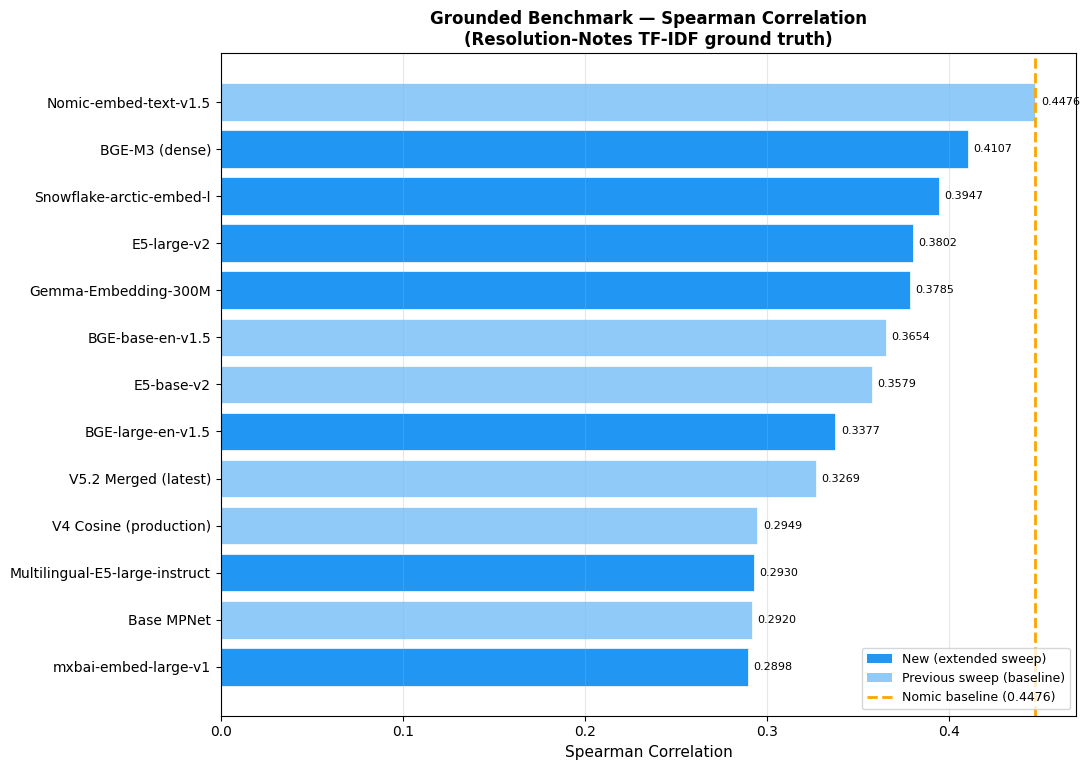

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\extended_sweep_grounded.png


In [32]:
# ── 7. Grounded Benchmark Chart (primary decision chart) ───────────────────
sem = df_all[df_all['Benchmark'] == 'v4_semantic_resnotes'].dropna(subset=['Spearman'])
sem = sem.sort_values('Spearman', ascending=True)   # horizontal bar — ascending = best at top

colors = [
    '#2196F3' if src == 'extended' else '#90CAF9'
    for src in sem['Source']
]

fig, ax = plt.subplots(figsize=(11, max(5, len(sem) * 0.6)))
bars = ax.barh(sem['Model'], sem['Spearman'], color=colors, edgecolor='white', linewidth=0.5)

# Annotate bars
for bar, sp in zip(bars, sem['Spearman']):
    ax.text(sp + 0.003, bar.get_y() + bar.get_height() / 2,
            f'{sp:.4f}', va='center', fontsize=8)

# Nomic baseline line
ax.axvline(0.4476, color='orange', linewidth=2, linestyle='--', label='Nomic baseline (0.4476)')

ax.set_xlabel('Spearman Correlation', fontsize=11)
ax.set_title('Grounded Benchmark — Spearman Correlation\n(Resolution-Notes TF-IDF ground truth)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.3)

# Legend for colours
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='New (extended sweep)'),
    Patch(facecolor='#90CAF9', label='Previous sweep (baseline)'),
]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color='orange',
          linewidth=2, linestyle='--', label='Nomic baseline (0.4476)')],
          fontsize=9, loc='lower right')

plt.tight_layout()
chart_path = EVAL_DIR / 'extended_sweep_grounded.png'
plt.savefig(chart_path, dpi=130, bbox_inches='tight')
plt.show()
print(f'[SAVE] {chart_path}')

In [33]:
# ── 8. Verdict ─────────────────────────────────────────────────────────────
sem_indexed = sem.set_index('Model')

print('=' * 80)
print('VERDICT — Grounded Benchmark (v4_semantic_resnotes)')
print(f'Baseline to beat : Nomic-embed-text-v1.5  Spearman={NOMIC_BASELINE}')
print('=' * 80)

NOMIC_BASELINE = 0.4476
winners = []

for model_name in sem_indexed.sort_values('Spearman', ascending=False).index:
    sp  = sem_indexed.loc[model_name, 'Spearman']
    roc = sem_indexed.loc[model_name, 'ROC-AUC']
    src = sem_indexed.loc[model_name, 'Source']
    tag = ''
    if sp > NOMIC_BASELINE:
        tag = '  ★ BEATS NOMIC — PRODUCTION CANDIDATE'
        winners.append(model_name)
    elif sp == NOMIC_BASELINE:
        tag = '  = NOMIC BASELINE'
    print(f'  {model_name:40s}  Sp={sp:.4f}  ROC={roc:.4f}{tag}')

print()
if winners:
    best = sem_indexed.loc[winners]['Spearman'].idxmax()
    best_sp = sem_indexed.loc[best, 'Spearman']
    print(f'RECOMMENDATION: Deploy {best} (Spearman={best_sp:.4f})')
    print(f'  → Improvement over current V4 Cosine production: +{best_sp - 0.2949:.4f}')
    print(f'  → Improvement over Nomic baseline: +{best_sp - NOMIC_BASELINE:.4f}')
else:
    print('No model beats Nomic zero-shot.')
    print('RECOMMENDATION: Deploy Nomic-embed-text-v1.5 as production (Spearman=0.4476)')
    print(f'  → Improvement over current V4 Cosine production: +{NOMIC_BASELINE - 0.2949:.4f}')

VERDICT — Grounded Benchmark (v4_semantic_resnotes)
Baseline to beat : Nomic-embed-text-v1.5  Spearman=0.4476
  Nomic-embed-text-v1.5                     Sp=0.4476  ROC=0.7584  = NOMIC BASELINE
  BGE-M3 (dense)                            Sp=0.4107  ROC=0.7371
  Snowflake-arctic-embed-l                  Sp=0.3947  ROC=0.7279
  E5-large-v2                               Sp=0.3802  ROC=0.7195
  Gemma-Embedding-300M                      Sp=0.3785  ROC=0.7185
  BGE-base-en-v1.5                          Sp=0.3654  ROC=0.7109
  E5-base-v2                                Sp=0.3579  ROC=0.7066
  BGE-large-en-v1.5                         Sp=0.3377  ROC=0.6950
  V5.2 Merged (latest)                      Sp=0.3269  ROC=0.6888
  V4 Cosine (production)                    Sp=0.2949  ROC=0.6702
  Multilingual-E5-large-instruct            Sp=0.2930  ROC=0.6692
  Base MPNet                                Sp=0.2920  ROC=0.6686
  mxbai-embed-large-v1                      Sp=0.2898  ROC=0.6673

No model beat